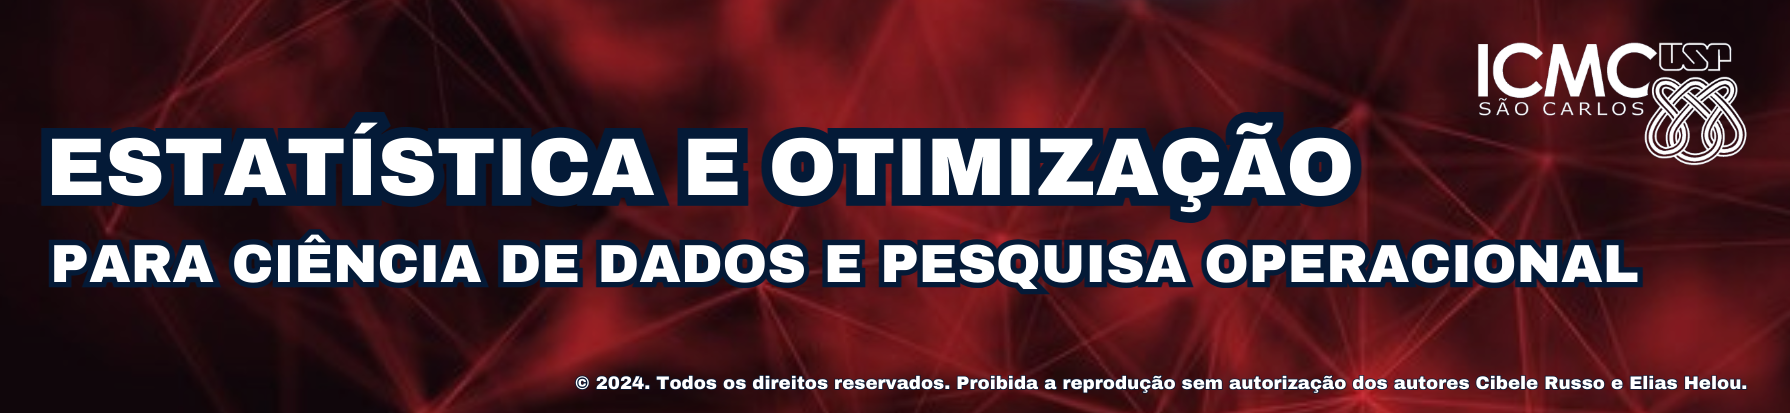

<h1 style = 'text-align: center;'>MLGs para dados de contagem</h1>

por **Cibele Russo**

**ICMC/USP - São Carlos SP**

## Conteúdo da aula

- Revisitando a família exponencial de distribuições

- Modelos Lineares Generalizados (MLGs)

- MLGs para dados de contagem

- Modelos Poisson e Binomial Negativa

- MLGs com enfoque Bayesiano

- Desafio: Como seria integrar essa modelagem com o Vehicle Routing Problem visto em otimização?

### Revisitando a família exponencial de distribuições

Seja $Y_i$ uma variável aleatória cuja distribuição pode ser escrita na forma


$$\large f(y,\theta_i, \phi) = exp[\phi\{y \theta_i - b(\theta_i)\} + c(y, \phi)]$$


Dizemos que a distribuição de $Y_i$ pertence à família exponencial e escrevemos $$\large Y_i \sim FE(\mu_i, \phi),$$


em que $\mu_i = E(Y_i) = b'(\theta_i)$ é o parâmetro de posição e $\phi^{-1}$ o parâmetro de dispersão.


Além disso, $Var(Y_i) = \phi^{-1}V_i$ com $V_i = \displaystyle\frac{d\mu}{d\theta}$ a **função de variância**.



Então dizemos que um MLG é determinado pela **função de ligação**
$g(\mu_i) = \eta_i$ e pela **função de variância** $V(\mu)$.



Valores de $b$, $\theta$, $\phi$ e $V(\mu)$ para algumas distribuições são apresentados na tabela a seguir

| Distribuição        | $b(\theta)$                     | $\theta$                                               | $\phi$         | $V(\mu)$             |
|---------------------|----------------------------------|--------------------------------------------------------|----------------|----------------------|
| Normal              | $\frac{\theta^2}{2}$            | $\mu$                                                  | $\sigma^{-2}$  | $1$                  |
| Binomial            | $\log(1 + e^{\theta})$          | $\log\left(\frac{\mu}{1 - \mu}\right)$                | $n$            | $\mu(1 - \mu)$       |
| Poisson             | $e^{\theta}$                    | $\log \mu$                                             | $1$            | $\mu$                |
| Binomial Negativa   | $-\log(1 - e^{\theta})$         | $\log\left(\frac{\mu}{1 + \phi \mu}\right)$           | $\phi$         | $\mu(1 + \phi \mu)$  |


## Modelos lineares generalizados

O modelo linear generalizado é definido por

$$\begin{array}{c}\large Y_i \sim FE(\mu_i, \phi) \\\large g(\mu_i) = \eta_i\end{array}$$

em que


- $ \eta_i = X_i^\top\beta$ é o **preditor linear**,

- $\beta = (\beta_0, \beta_1,\ldots, \beta_p)^\top$, $p<n$ é um vetor de parâmetros desconhecidos (coeficientes da regressão),

- $ X_i = (1, X_{i1},\ldots, X_{ip})^\top$ representa os valores de $p$ variáveis preditoras e

- $g(\mu_i)$ é a **função de ligação**, uma função monótona e diferenciável.

- $\phi^{-1}$ o parâmetro de dispersão




### Modelos para dados de contagem: Poisson, Binomial Negativa

#### Distribuição de Poisson

Se $Y\sim P(\mu)$, com densidade dada por

$$ f(y) =P(Y=y) =   \displaystyle\frac{e^{-\mu} \mu^y}{y!} = exp(y \log\mu -\mu -\log y!), $$

em que $\mu>0$ e $y=0,1,...$

Essa densidade pode ser escrita na forma da família exponencial:

$$
f(y) = \exp\left( y \theta - b(\theta) + c(y, \phi) \right),
$$

com $\theta = \log\mu$, $b(\theta) = e^\theta$, $\phi=1$ e $c(y, \phi) = -\log y!$. 


Segue que $V(\mu) = \mu$ 

(variância populacional = média populacional).






#### Distribuição Binomial Negativa: para dados de contagem (quando média < variância, sobredispersão)

Se $Y \sim \text{BN}(\mu, \phi)$, com densidade dada por

$$f(y) = \binom{y + \frac{1}{\phi} - 1}{y} \left( \frac{1}{1 + \phi \mu} \right)^{1/\phi} \left( \frac{\phi \mu}{1 + \phi \mu} \right)^y,$$

para $y = 0, 1, 2, \ldots$, com $\mu > 0$ e $\phi > 0$.

Essa densidade pode ser escrita na forma da família exponencial:

$$
f(y) = \exp\left( y \theta - b(\theta) + c(y, \phi) \right),
$$

com: $
\theta = \log\left( \frac{\mu}{1 + \phi \mu} \right), \quad 
b(\theta) = -\log(1 - e^{\theta}), \quad 
\phi = \text{parâmetro de dispersão},$

$
c(y, \phi) = \log\Gamma\left(y + \frac{1}{\phi} \right) - \log(y!) - \log\Gamma\left( \frac{1}{\phi} \right) - \frac{1}{\phi} \log(1 + \phi \mu).
$

Segue que a variância é:

$$
V(\mu) = \mu(1 + \phi \mu).
$$


#### Ilustração das f.m.p de Poisson e Binomial Negativa

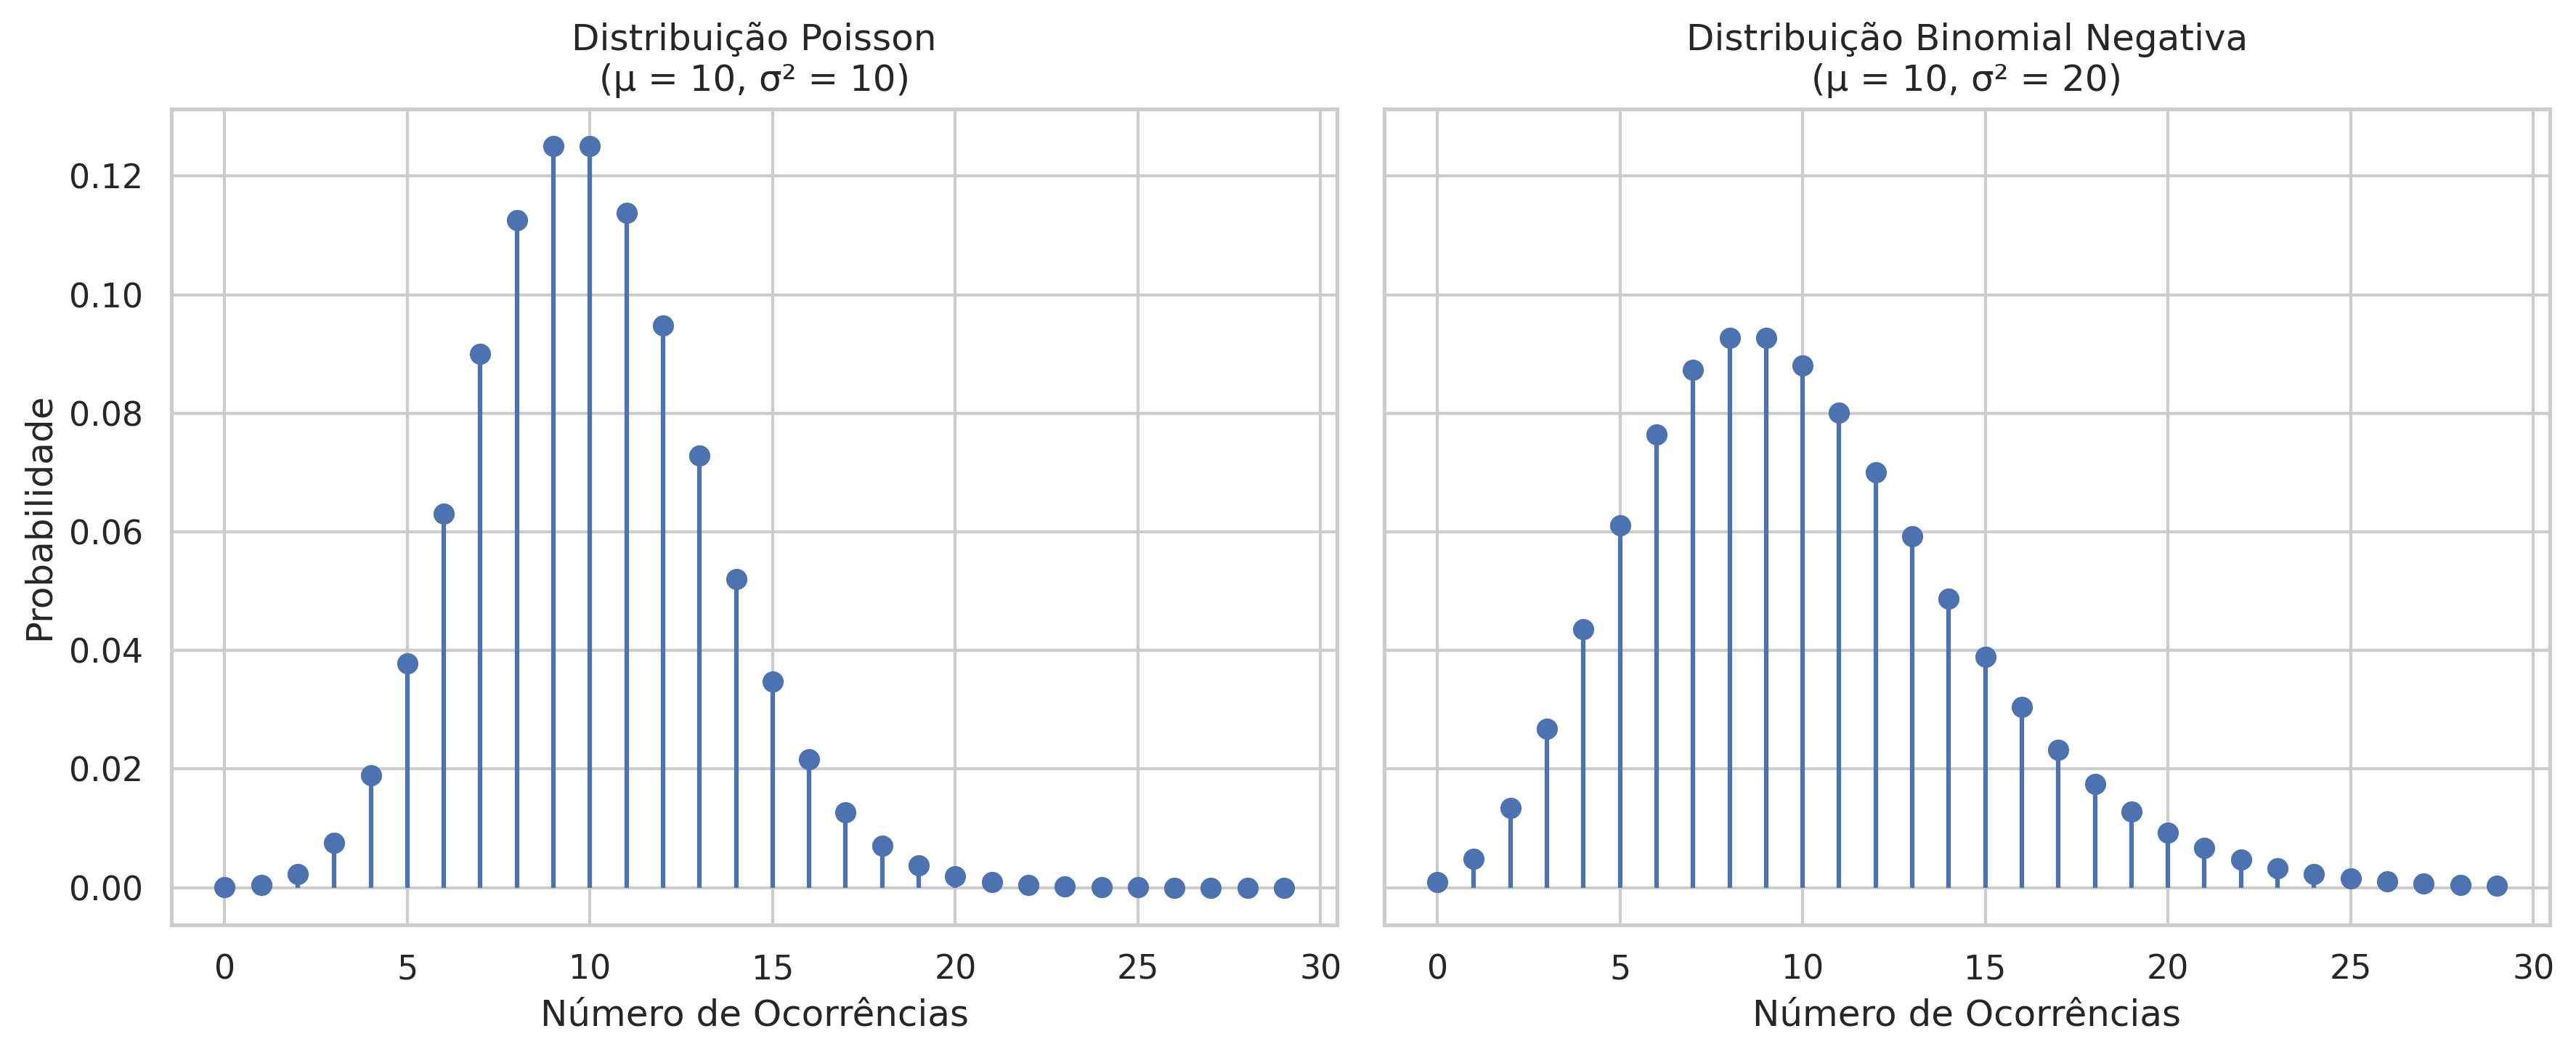

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, nbinom

# Parâmetros
mu = 10               # Média para ambas as distribuições
var_poisson = mu      # Variância da Poisson (igual à média)
var_nb = 20           # Variância para Binomial Negativa (> mu: sobredispersão)

# Definir intervalo de valores (suporte)
k_vals = np.arange(0, 30)

# Função massa de probabilidade da Poisson
pmf_poisson = poisson(mu).pmf(k_vals)

# Parâmetros da binomial negativa a partir de mu e var
alpha = (var_nb - mu) / mu**2  # alpha = 1/r
r = 1 / alpha
p = r / (r + mu)
# Função massa de probabilidade da binomial negativa
pmf_nb = nbinom(n=r, p=p).pmf(k_vals)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, dpi=300)

# Poisson
axes[0].stem(k_vals, pmf_poisson, linefmt='C0-', markerfmt='C0o', basefmt=" ")
axes[0].set_title("Distribuição Poisson\n(μ = 10, σ² = 10)")
axes[0].set_xlabel("Número de Ocorrências")
axes[0].set_ylabel("Probabilidade")
axes[0].grid(True)

# Binomial Negativa
axes[1].stem(k_vals, pmf_nb,  basefmt=" ")
axes[1].set_title("Distribuição Binomial Negativa\n(μ = 10, σ² = 20)")
axes[1].set_xlabel("Número de Ocorrências")
axes[1].grid(True)

plt.tight_layout()
plt.show()


#### Aplicação: Dados de pedidos para entrega

Considere dados de uma empresa que realiza entregas. Foram registrados dados de 100 pedidos, com as seguintes informações:

- tipo de cliente
- canal de venda
- categoria de produto
- dia da semana em que foi realizado o pedido
- promoção
- tempo de entrega previsto
- número de produtos na compra
- localização da entrega

**O interesse principal é modelar o número de produtos em cada compra (contagem), de acordo com as diversas variáveis preditoras disponíveis.**

Exercício: Classifique as variáveis.


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4), dpi=300) 

url='https://raw.githubusercontent.com/cibelerusso/Datasets/refs/heads/main/pedidos.csv'

df = pd.read_csv(url,index_col=0)
df

,tipo_cliente,canal_venda,categoria_produto,dia_semana,promocao,tempo_entrega_previsto,num_produtos,localizacao,x,y
0,consumidor,loja_fisica,vestuário,segunda,sim,4,30,"(0, -640)",0,-640
1,consumidor,revendedor,escritório,quarta,não,2,7,"(912, -400)",912,-400
2,empresa,online,alimentos,sexta,não,2,3,"(570, -160)",570,-160
3,empresa,loja_fisica,eletrônico,terça,não,2,26,"(912, 0)",912,0
4,consumidor,loja_fisica,alimentos,quinta,sim,5,5,"(114, -80)",114,-80
...,...,...,...,...,...,...,...,...,...,...
95,empresa,online,escritório,quarta,sim,3,2,"(342, -240)",342,-240
96,empresa,revendedor,alimentos,terça,não,2,3,"(114, -80)",114,-80
97,consumidor,loja_fisica,escritório,quinta,sim,3,9,"(0, -80)",0,-80
98,empresa,online,vestuário,quinta,não,4,4,"(684, -560)",684,-560


<Figure size 2400x1200 with 0 Axes>

### Análise Exploratória de Dados

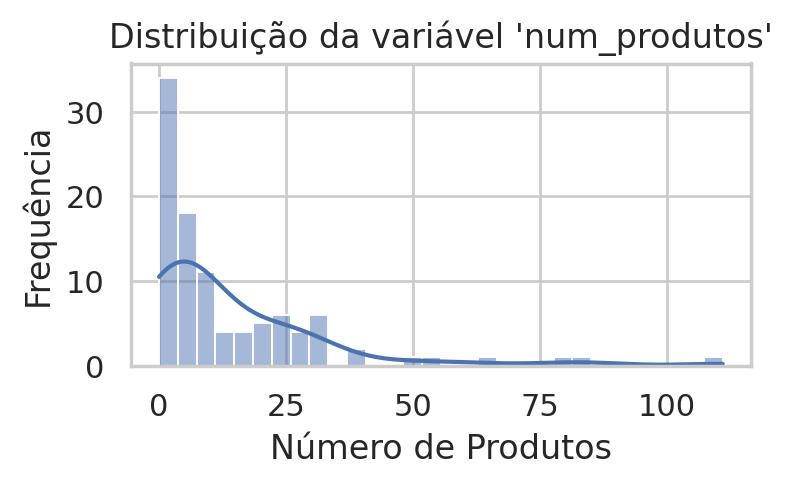

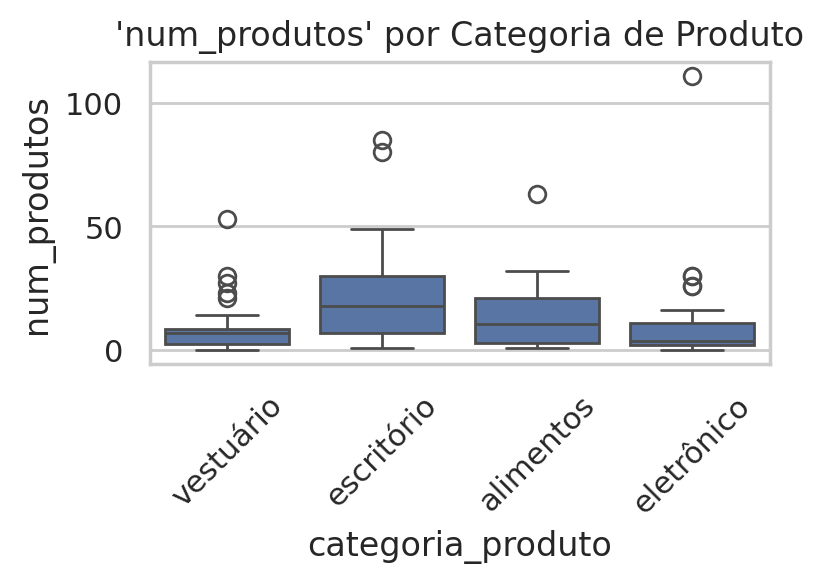

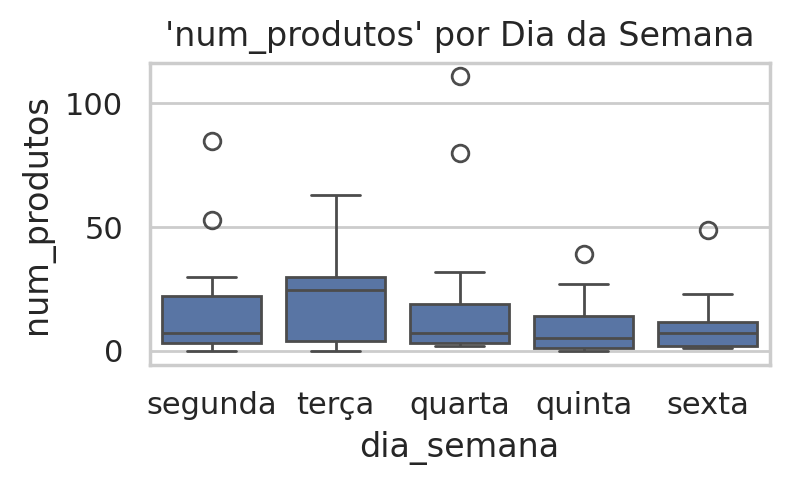

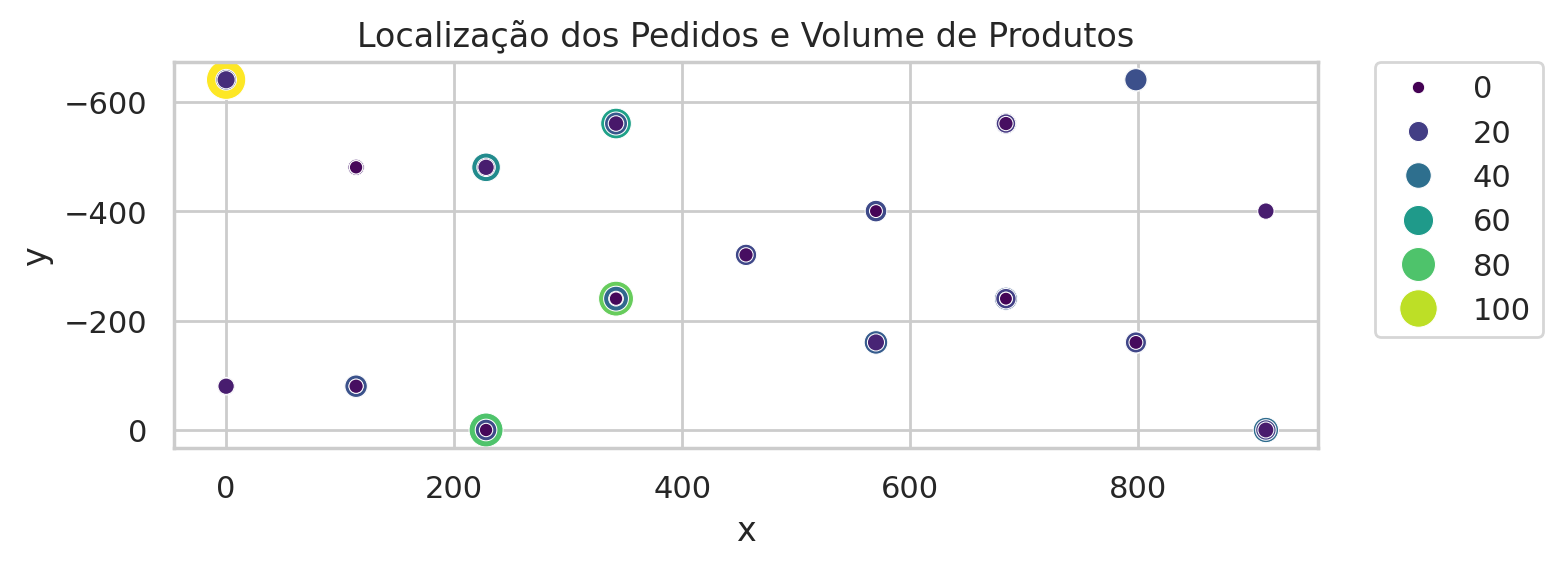

In [62]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ajustar estilo
sns.set_theme(style="whitegrid")

# Distribuição de 'num_produtos'
plt.figure(figsize=(4,2), dpi=200) 
sns.histplot(df['num_produtos'], bins=30, kde=True)
plt.title("Distribuição da variável 'num_produtos'")
plt.xlabel("Número de Produtos")
plt.ylabel("Frequência")
plt.show()

# Boxplot de 'num_produtos' por 'categoria_produto'
plt.figure(figsize=(4,2), dpi=200) 
sns.boxplot(x='categoria_produto', y='num_produtos', data=df)
plt.title("'num_produtos' por Categoria de Produto")
plt.xticks(rotation=45)
plt.show()

#  Boxplot de 'num_produtos' por 'dia_semana'
plt.figure(figsize=(4,2), dpi=200) 
sns.boxplot(x='dia_semana', y='num_produtos', data=df, order=['segunda', 'terça', 'quarta', 'quinta', 'sexta'])
plt.title("'num_produtos' por Dia da Semana")
plt.show()

# Localização e volume dos pedidos
plt.figure(figsize=(8, 3), dpi=200)
scatter = sns.scatterplot(
    x='x', y='y', size='num_produtos', hue='num_produtos',
    data=df, sizes=(20, 200), palette='viridis'
)
plt.title("Localização dos Pedidos e Volume de Produtos")
plt.gca().invert_yaxis()
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()


In [63]:
# Variáveis dummy para as variáveis categóricas
vars_categoricas = ['tipo_cliente', 'canal_venda', 'categoria_produto', 'dia_semana', 'promocao']
preditoras = pd.get_dummies(df[vars_categoricas + ['tempo_entrega_previsto']], drop_first=True).astype(float)


In [81]:
preditoras


,tempo_entrega_previsto,tipo_cliente_empresa,canal_venda_online,canal_venda_revendedor,categoria_produto_eletrônico,categoria_produto_escritório,categoria_produto_vestuário,dia_semana_quinta,dia_semana_segunda,dia_semana_sexta,dia_semana_terça,promocao_sim
0,4.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
1,2.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,2.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,5.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
95,3.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
96,2.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
97,3.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
98,4.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0


In [64]:
import statsmodels.api as sm
from statsmodels.tools import add_constant
from statsmodels.genmod.families.links import Log

# Ajustar modelo Poisson (GLM)
X = sm.add_constant(preditoras)
y = df['num_produtos']
model = sm.GLM(y, X, family=sm.families.Poisson(link=Log()))
results = model.fit()

# Visualizar resumo
print(results.summary())

# Extrair demanda
demanda = df['num_produtos'].tolist()
demanda[0] = 0  # depósito

                 Generalized Linear Model Regression Results                  
Dep. Variable:           num_produtos   No. Observations:                  100
Model:                            GLM   Df Residuals:                       87
Model Family:                 Poisson   Df Model:                           12
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -694.61
Date:                Wed, 14 May 2025   Deviance:                       1012.8
Time:                        19:44:04   Pearson chi2:                 1.09e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.9995
Covariance Type:            nonrobust                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

In [65]:
deviance = results.deviance
df_resid = results.df_resid
dispersion = deviance / df_resid


In [66]:
dispersion

np.float64(11.64179092443309)

In [67]:
df['num_produtos'].mean(), df['num_produtos'].var()

(np.float64(14.31), 353.1857575757576)

In [ ]:
def envelope_poisson(fitted_model, X, title):
    resid_dev = fitted_model.resid_deviance.copy()
    sorted_resid = np.sort(resid_dev)

    sim_resid = []
    for _ in range(100):
        mu_sim = np.clip(fitted_model.fittedvalues, 1e-3, 1e5)
        y_sim = np.random.poisson(mu_sim)
        sim_model = sm.GLM(y_sim, X, family=sm.families.Poisson()).fit()
        sim_resid.append(np.sort(sim_model.resid_deviance))

    sim_resid = np.array(sim_resid)
    lower = np.percentile(sim_resid, 2.5, axis=0)
    upper = np.percentile(sim_resid, 97.5, axis=0)

    plt.plot(sorted_resid, 'o', label="Resíduos observados")
    plt.plot(lower, 'r--', linewidth=1, label="banda 2.5%")
    plt.plot(upper, 'r--', linewidth=1, label="banda 97.5%")
    plt.title(title)
    plt.xlabel("Ordem dos resíduos")
    plt.ylabel("Resíduo de Deviance")
    plt.legend()
    plt.grid(True)

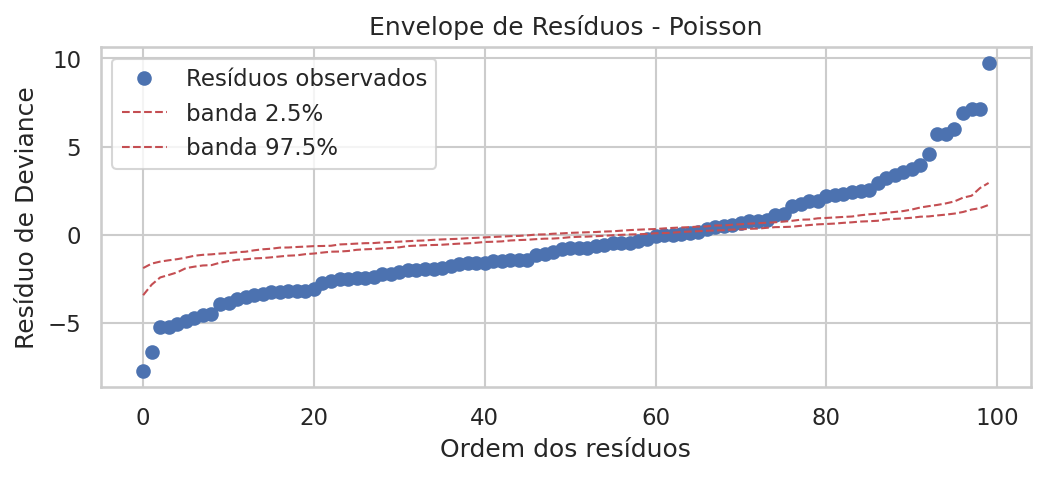

In [69]:
plt.figure(figsize=(8, 3), dpi=150) 
envelope_poisson(results, X, "Envelope de Resíduos - Poisson")

### Interpretação dos coeficientes no modelo de regressão Poisson

Em um modelo de regressão Poisson, assumimos que a variável resposta $Y_i$ tem distribuição

$$
Y_i \sim \text{Poisson}(\mu_i), \quad \text{com} \quad \log(\mu_i) = \beta_0 + \beta_1 x_{1i} + \beta_2 x_{2i} + \dots + \beta_p x_{pi}
$$

ou, equivalentemente:

$$
\mu_i = \exp(\beta_0 + \beta_1 x_{1i} + \dots + \beta_p x_{pi})
$$


#### Interpretação dos coeficientes:

- O coeficiente $\beta_j$ representa o efeito de uma variação de uma unidade na variável explicativa $x_j$ sobre o **logaritmo da contagem esperada** $\mu_i$.
  
- A quantidade $\exp(\beta_j)$ representa a **razão de taxas** (rate ratio), ou seja, o **fator multiplicativo** na contagem esperada associada a um aumento de uma unidade em $x_j$, mantendo as demais variáveis constantes:
  
$$
  \exp(\beta_j) = \frac{\mu_i(x_j + 1)}{\mu_i(x_j)}
$$
  
- Se $\beta_j = 0.5914$ (promoção_sim), então $\exp(0.5914) \approx 1.8$: a contagem esperada aumenta 80% quando há promoção.
- Se $\beta_j = -0.5327$ (canal de venda revendedor), então $\exp(-0.5327) \approx 0.59$: a contagem esperada é reduzida em cerca de 41\% para canal de venda revendedor $x_j$ em relação a loja física.



**Observação:** essa interpretação é diferente da regressão logística, em que $\exp(\beta_j)$ representa uma **razão de chances** (odds ratio). No caso da Poisson, interpretamos como **razão de taxas**.


In [70]:
np.exp(0.5914)

np.float64(1.806515767913374)

In [71]:
np.exp(-0.5327)

np.float64(0.5870178797957222)

# Sobredispersão

## Pode fazer sentido um modelo binomial negativo

In [91]:
model_nb = sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=0.76))
results_nb = model_nb.fit()


In [92]:
# Visualizar resumo
print(results_nb.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           num_produtos   No. Observations:                  100
Model:                            GLM   Df Residuals:                       87
Model Family:        NegativeBinomial   Df Model:                           12
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -343.89
Date:                Wed, 14 May 2025   Deviance:                       108.96
Time:                        20:46:05   Pearson chi2:                     97.9
No. Iterations:                    15   Pseudo R-squ. (CS):             0.4619
Covariance Type:            nonrobust                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

In [89]:
from statsmodels.discrete.discrete_model import NegativeBinomial

# Ajustar o modelo binomial negativa com alpha estimado
nb_model = NegativeBinomial(y, X)
nb_results = nb_model.fit(maxiter=100)
alpha_est = nb_results.params.iloc[-1]

print(f"Alpha estimado (a partir do modelo discreto): {np.exp(alpha_est):.4f}")


Optimization terminated successfully.
         Current function value: 3.438851
         Iterations: 35
         Function evaluations: 37
         Gradient evaluations: 37
Alpha estimado (a partir do modelo discreto): 2.1402


In [90]:
np.log(2.14)

np.float64(0.7608058290337602)

**Exercício:** verifique qual o método de otimização utilizado acima

In [93]:
def envelope_negbin(fitted_model, X, title, alpha):
    resid_dev = fitted_model.resid_deviance.copy()
    sorted_resid = np.sort(resid_dev)

    sim_resid = []
    for _ in range(100):
        mu_sim = np.clip(fitted_model.fittedvalues, 1e-3, 1e5)
        n_sim = 1 / alpha
        p_sim = n_sim / (n_sim + mu_sim)
        y_sim = np.random.negative_binomial(n=n_sim, p=p_sim)
        sim_model = sm.GLM(y_sim, X, family=sm.families.NegativeBinomial(alpha=alpha)).fit()
        sim_resid.append(np.sort(sim_model.resid_deviance))

    sim_resid = np.array(sim_resid)
    lower = np.percentile(sim_resid, 2.5, axis=0)
    upper = np.percentile(sim_resid, 97.5, axis=0)

    plt.plot(sorted_resid, 'o', label="Resíduos observados")
    plt.plot(lower, 'r--', linewidth=1, label="banda 2.5%")
    plt.plot(upper, 'r--', linewidth=1, label="banda 97.5%")
    plt.title(title)
    plt.xlabel("Ordem dos resíduos")
    plt.ylabel("Resíduo de Deviance")
    plt.legend()
    plt.grid(True)

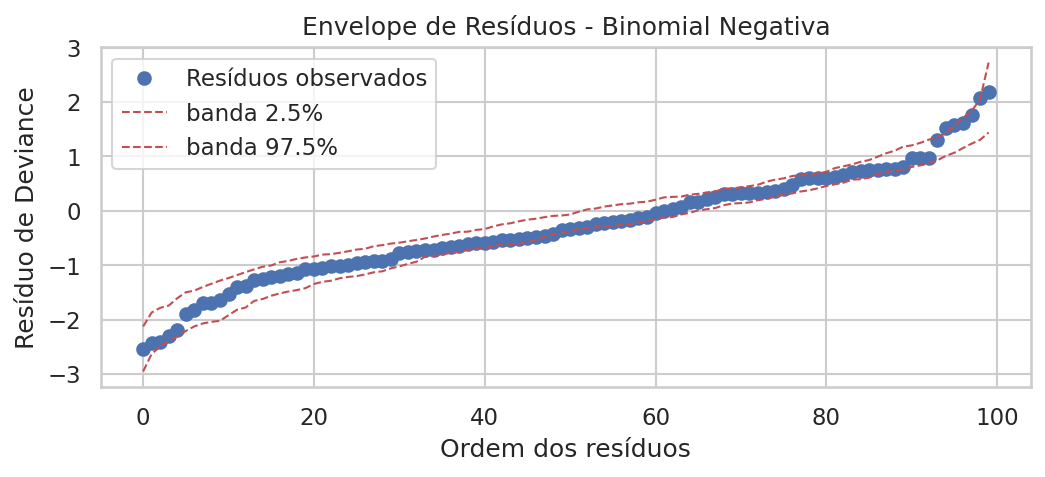

In [94]:
alpha = alpha_est
plt.figure(figsize=(8, 3), dpi=150) 
envelope_negbin(results_nb, X, "Envelope de Resíduos - Binomial Negativa", alpha=alpha)


**Exercício:** 

Refaça a modelagem usando statsmodels considerando bases de treinamento e teste e avalie os ajustes com métricas MSE, RMSE, MAE

## Modelos bayesianos com programação probabilística via PyMC

In [ ]:
import pymc as pm
import arviz as az

# Modelo Bayesiano com Poisson
with pm.Model() as poisson_model:

    # Prioris
    coefs = pm.Normal("coefs", mu=0, sigma=2, shape=X.shape[1])

    # Modelo
    mu = pm.math.exp(pm.math.dot(X.values, coefs))  # log-link implícito

    # Resposta Poisson
    y_obs = pm.Poisson("y_obs", mu=mu, observed=y.values)  # não usar log(y)

    # Amostragem da Posteriori
    trace_poisson = pm.sample(1000, tune=1000, target_accept=0.9, return_inferencedata=True)

az.summary(trace_poisson, var_names=["coefs"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [coefs]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 11 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
coefs[0],1.182,0.121,0.966,1.411,0.003,0.002,1719.0,2225.0,1.0
coefs[1],0.296,0.021,0.257,0.333,0.000,0.000,3037.0,2853.0,1.0
coefs[2],0.466,0.061,0.353,0.583,0.001,0.001,2456.0,2334.0,1.0
coefs[3],-0.147,0.074,-0.276,0.002,0.001,0.001,2547.0,2943.0,1.0
coefs[4],-0.531,0.088,-0.693,-0.364,0.002,0.001,2565.0,2633.0,1.0
coefs[5],0.039,0.082,-0.109,0.196,0.002,0.001,2443.0,2478.0,1.0
coefs[6],0.650,0.076,0.505,0.788,0.002,0.001,2336.0,2601.0,1.0
coefs[7],-0.180,0.088,-0.345,-0.014,0.002,0.001,2622.0,3035.0,1.0
coefs[8],-0.488,0.089,-0.649,-0.318,0.002,0.001,2966.0,2881.0,1.0
coefs[9],0.520,0.081,0.361,0.663,0.002,0.001,2374.0,2563.0,1.0


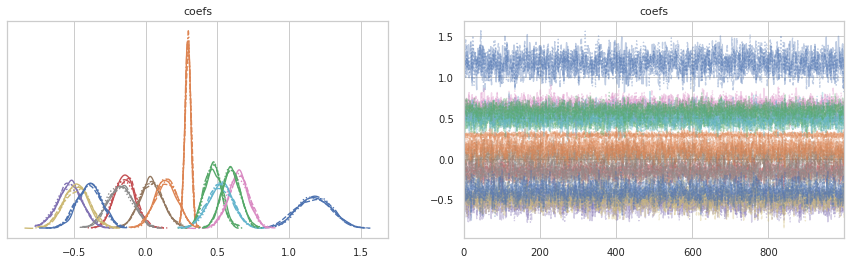

In [78]:
import arviz as az

az.plot_trace(trace_poisson, var_names=['coefs'], figsize=(15,4));


### Modelo Binomial Negativo com enfoque Bayesiano

In [79]:
# Modelo no formato compacto

import pymc as pm
import arviz as az

with pm.Model() as nb_model:
    # Priori para os coeficientes: todas normais
    coefs = pm.Normal("coefs", mu=0, sigma=2, shape=X.shape[1])

    # Priori para a dispersão (alpha > 0): half normal
    alpha = pm.HalfNormal("alpha", sigma=1)

    # Link log: log(mu) = Xβ => mu = exp(Xβ)
    mu = pm.math.exp(pm.math.dot(X.values, coefs))

    # Modelo Binomial Negativa com média mu e dispersão alpha
    y_obs = pm.NegativeBinomial("y_obs", mu=mu, alpha=alpha, observed=y.values)

    # Amostragem da posteriori
#    trace_nb = pm.sample(1000, tune=1000, target_accept=0.9, return_inferencedata=True)

# Resumo dos resultados
#az.summary(trace_nb, var_names=["coefs", "alpha"])


In [ ]:
# Formato alternativo: com modelo expandido

import pymc as pm
import arviz as az

with pm.Model() as nb_model:
    # Prioris para cada coeficiente
    beta0  = pm.Normal("beta0",  mu=0, sigma=2)
    beta1  = pm.Normal("beta1",  mu=0, sigma=2)  # tempo_entrega_previsto
    beta2  = pm.Normal("beta2",  mu=0, sigma=2)  # tipo_cliente_empresa
    beta3  = pm.Normal("beta3",  mu=0, sigma=2)  # canal_venda_online
    beta4  = pm.Normal("beta4",  mu=0, sigma=2)  # canal_venda_revendedor
    beta5  = pm.Normal("beta5",  mu=0, sigma=2)  # categoria_produto_eletrônico
    beta6  = pm.Normal("beta6",  mu=0, sigma=2)  # categoria_produto_escritório
    beta7  = pm.Normal("beta7",  mu=0, sigma=2)  # categoria_produto_vestuário
    beta8  = pm.Normal("beta8",  mu=0, sigma=2)  # dia_semana_quinta
    beta9  = pm.Normal("beta9",  mu=0, sigma=2)  # dia_semana_segunda
    beta10 = pm.Normal("beta10", mu=0, sigma=2)  # dia_semana_sexta
    beta11 = pm.Normal("beta11", mu=0, sigma=2)  # dia_semana_terça
    beta12 = pm.Normal("beta12", mu=0, sigma=2)  # promocao_sim

    # Prior para a dispersão (alpha > 0)
    alpha = pm.HalfNormal("alpha", sigma=1)

    # Previsão da média com link log
    mu = pm.math.exp(
        beta0
        + beta1 * X["tempo_entrega_previsto"].values
        + beta2 * X["tipo_cliente_empresa"].values
        + beta3 * X["canal_venda_online"].values
        + beta4 * X["canal_venda_revendedor"].values
        + beta5 * X["categoria_produto_eletrônico"].values
        + beta6 * X["categoria_produto_escritório"].values
        + beta7 * X["categoria_produto_vestuário"].values
        + beta8 * X["dia_semana_quinta"].values
        + beta9 * X["dia_semana_segunda"].values
        + beta10 * X["dia_semana_sexta"].values
        + beta11 * X["dia_semana_terça"].values
        + beta12 * X["promocao_sim"].values
    )

    # Modelo Binomial Negativa com média mu e dispersão alpha
    y_obs = pm.NegativeBinomial("y_obs", mu=mu, alpha=alpha, observed=y.values)

    # Amostragem da Posteriori
    trace_nb = pm.sample(1000, tune=1000, target_accept=0.9, return_inferencedata=True)

# Resumo dos resultados com nomes corretos
az.summary(
    trace_nb,
    var_names=[
        "beta0", "beta1", "beta2", "beta3", "beta4", "beta5", "beta6",
        "beta7", "beta8", "beta9", "beta10", "beta11", "beta12", "alpha"
    ]
)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta0, beta1, beta2, beta3, beta4, beta5, beta6, beta7, beta8, beta9, beta10, beta11, beta12, alpha]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 8 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta0,1.284,0.382,0.552,1.991,0.009,0.005,1899.0,2511.0,1.0
beta1,0.272,0.077,0.125,0.409,0.002,0.001,2539.0,2749.0,1.0
beta2,0.572,0.221,0.177,0.991,0.004,0.003,3073.0,3013.0,1.0
beta3,-0.199,0.261,-0.678,0.306,0.005,0.004,2567.0,3057.0,1.0
beta4,-0.625,0.320,-1.240,-0.047,0.006,0.005,2700.0,2695.0,1.0
beta5,-0.203,0.294,-0.753,0.356,0.005,0.004,2965.0,3036.0,1.0
beta6,0.751,0.301,0.178,1.308,0.006,0.004,2857.0,2878.0,1.0
beta7,-0.170,0.298,-0.697,0.433,0.006,0.004,2865.0,2583.0,1.0
beta8,-0.355,0.316,-0.945,0.247,0.006,0.005,2598.0,2544.0,1.0
beta9,0.485,0.362,-0.231,1.114,0.007,0.005,2891.0,2999.0,1.0


### Desafio

Como seria integrar essa modelagem com a metodologia de otimização para o Vehicle Routing Problem? (Aula 2 ODI vídeo 4)


Algumas ideias

- Incluir a capacidade máxima para entregas dos veículos como uma variável na modelagem.

- Modelar quantas entregas poderiam ser feitas em cada viagem.

- Obter amostras de, digamos, 10 pedidos, e calcular a rota para entregas.


